In [18]:
# Cell 1: Imports
import os
import ast
from typing import Tuple, List, Dict
import pandas as pd
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (classification_report, roc_auc_score, roc_curve,
                             precision_recall_curve, average_precision_score, confusion_matrix)
import joblib



In [19]:
# Cell 2: Load CSVs
base_path = '.'  # Thay đổi đường dẫn nếu cần

files = {
    'users': os.path.join(base_path, 'users.csv'),
    'worlds': os.path.join(base_path, 'vrworld.csv'),
    'actions': os.path.join(base_path, 'user_actions.csv'),
    'achievements': os.path.join(base_path, 'achievements.csv'),
    'connections': os.path.join(base_path, 'connections.csv')
}

data = {}
for k, path in files.items():
    if os.path.exists(path):
        data[k] = pd.read_csv(path, dtype=str)
        print(f"Loaded {k}: {len(data[k])} rows")
    else:
        print(f"Warning: {path} not found. Creating empty DataFrame for {k}.")
        data[k] = pd.DataFrame()

users = data['users']
worlds = data['worlds']
actions = data['actions']

# Show first few rows
users.head(), worlds.head(), actions.head()


Loaded users: 300 rows
Loaded worlds: 80 rows
Loaded actions: 3000 rows
Loaded achievements: 1000 rows
Loaded connections: 1000 rows


(   user_id           user_name is_creator         region preferred_language  \
 0  U611761    EpicExplorer9016      false        us-east                 fr   
 1  U626752  ShadowExplorer3545      false           asia                 ko   
 2  U979151      EpicWizard2512      false           asia                 ko   
 3  U236085    ShadowDragon3178       true  south-america                 en   
 4  U725994    ShadowPlayer3316      false           asia                 de   
 
   age_group content_filter_level       preferred_categories  
 0     25-34               medium             Art & Creative  
 1     18-24                 high       Social,Gaming,Social  
 2     25-34                  low  Adventure,Roleplay,Social  
 3     13-17                  low       Social,Puzzle,Social  
 4     18-24                 none                   Roleplay  ,
    world_id     world_name       creator_name   category sub_category  \
 0  W1559620     Neon Arena  MysticCreator6163     Social      Po

In [20]:
# Cell 3: Create binary target (liked or not)
def make_target(actions: pd.DataFrame) -> pd.DataFrame:
    if actions.empty:
        return pd.DataFrame(columns=['user_id', 'world_id', 'liked'])
    
    acts = actions.copy()
    acts['action_type'] = acts['action_type'].astype(str)
    liked = acts[acts['action_type'] == 'world_like'][['user_id', 'world_id']].drop_duplicates()
    liked['liked'] = 1

    pairs = acts[['user_id', 'world_id']].drop_duplicates()
    pairs = pairs.merge(liked, on=['user_id', 'world_id'], how='left')
    pairs['liked'] = pairs['liked'].fillna(0).astype(int)
    return pairs

pairs = make_target(actions)
print(f"Prepared {len(pairs)} user-world pairs")
pairs.head()



Prepared 2812 user-world pairs


,user_id,world_id,liked
0,U293528,W1347319,0
1,U418527,W1559620,0
2,U312829,W9028709,0
3,U869645,W5972066,0
4,U436983,W7310015,0


In [46]:
# Cell 4: Build features (fixed numeric conversion)
def build_features(pairs, users, worlds, actions):
    df = pairs.copy()

    # Merge user info
    user_cols = ['user_id', 'is_creator', 'region', 'preferred_language', 'age_group', 'content_filter_level']
    df = df.merge(users[user_cols], on='user_id', how='left')
    
    # Merge world info
    world_cols = ['world_id','category','sub_category','avg_session_minutes','rating','total_ratings','likes','max_players','is_featured']
    df = df.merge(worlds[world_cols], on='world_id', how='left')

    # Interaction features
    actions['ts'] = pd.to_datetime(actions['action_timestamp'], errors='coerce')
    agg = actions.groupby(['user_id', 'world_id']).agg(
        actions_count=('action_id', 'count'),
        unique_actions=('action_type', lambda x: x.nunique()),
        last_action_ts=('ts', 'max'),
        avg_rating_given=('action_value', lambda x: pd.to_numeric(x, errors='coerce').mean())
    ).reset_index()
    df = df.merge(agg, on=['user_id', 'world_id'], how='left')

    df['actions_count'] = df['actions_count'].fillna(0)
    df['unique_actions'] = df['unique_actions'].fillna(0)
    df['avg_rating_given'] = df['avg_rating_given'].fillna(0)

    # Time since last action (days)
    now = pd.Timestamp.now()
    df['last_action_days'] = (now - pd.to_datetime(df['last_action_ts'], errors='coerce')).dt.total_seconds() / (3600*24)
    df['last_action_days'] = df['last_action_days'].fillna(999).clip(0, 999)

    # --- Numeric cleaning ---
    numeric_cols = ['avg_session_minutes','rating','total_ratings','likes','max_players']
    for col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors='coerce')
        median_val = df[col].median()
        df[col] = df[col].fillna(median_val)

    # Simple engineered features
    df['likes_per_rating'] = df.apply(lambda r: r['likes']/r['total_ratings'] if r['total_ratings']>0 else 0, axis=1)

    # Convert categorical boolean columns to int
    df['is_featured'] = df['is_featured'].map({'true':1,'false':0}).fillna(0).astype(int)
    df['is_creator'] = df['is_creator'].map({'true':1,'false':0}).fillna(0).astype(int)

    return df

# Apply the function
df = build_features(pairs, users, worlds, actions)
df.head()


,user_id,world_id,liked,is_creator,region,preferred_language,age_group,content_filter_level,category,sub_category,...,total_ratings,likes,max_players,is_featured,actions_count,unique_actions,last_action_ts,avg_rating_given,last_action_days,likes_per_rating
0,U293528,W1347319,0,0,oceania,it,35-44,medium,Social,Popular,...,4244,8483,100,1,2,2,2025-08-21 20:44:09,0.0,15.970507,1.998822
1,U418527,W1559620,0,0,asia,en,25-34,low,Social,Popular,...,5715,3000,16,0,1,1,2025-06-22 23:13:09,0.0,75.867035,0.524934
2,U312829,W9028709,0,0,europe,en,18-24,medium,Gaming,Popular,...,1837,15612,8,0,2,1,2025-08-24 00:58:09,0.0,13.794118,8.498639
3,U869645,W5972066,0,0,asia,ja,35-44,medium,Art & Creative,Featured,...,7830,12956,16,0,1,1,2025-07-15 05:20:09,1.0,53.612174,1.654662
4,U436983,W7310015,0,1,us-west,de,18-24,high,Social,Featured,...,3790,9903,4,0,1,1,2025-07-15 15:42:09,1.0,53.180229,2.612929


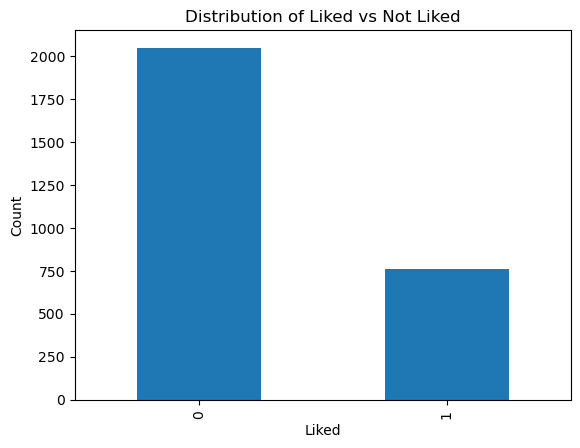

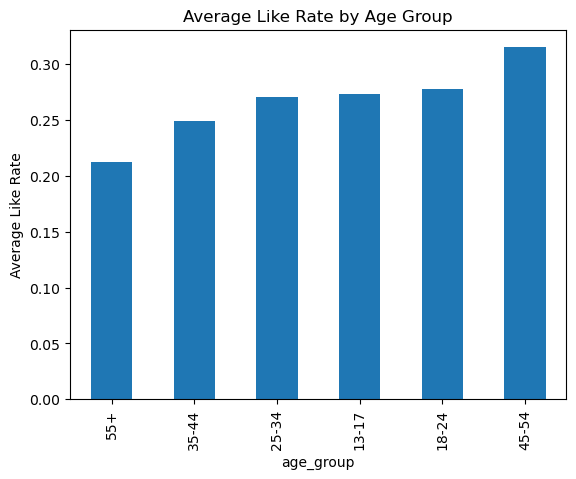

In [23]:
# Cell 5: Exploratory plots
# Distribution of target
df['liked'].value_counts().plot(kind='bar', title='Distribution of Liked vs Not Liked')
plt.xlabel('Liked')
plt.ylabel('Count')
plt.show()

# Age group vs liked rate
age_liked = df.groupby('age_group')['liked'].mean().sort_values()
age_liked.plot(kind='bar', title='Average Like Rate by Age Group')
plt.ylabel('Average Like Rate')
plt.show()


In [25]:
# Cell 6: Feature/target split
target = 'liked'
feature_cols = [
    'is_creator','region','preferred_language','age_group','content_filter_level',
    'category','sub_category','avg_session_minutes','rating','total_ratings','likes','max_players','is_featured',
    'actions_count','unique_actions','avg_rating_given','last_action_days','likes_per_rating'
]

X = df[feature_cols].copy()
y = df[target].astype(int)

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

numeric = ['avg_session_minutes','rating','total_ratings','likes','max_players',
           'actions_count','unique_actions','avg_rating_given','last_action_days','likes_per_rating']
categorical = ['is_creator','region','preferred_language','age_group','content_filter_level','category','sub_category','is_featured']

def make_preprocessor(categorical, numeric):
    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse=False))
    ])
    num_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    return ColumnTransformer([
        ('num', num_pipe, numeric),
        ('cat', cat_pipe, categorical)
    ])

preprocessor = make_preprocessor(categorical, numeric)


In [26]:
# Cell 7: Train 4 models
models_dict = {
    'LogisticRegression': LogisticRegression(max_iter=1000),
    'DecisionTree': DecisionTreeClassifier(max_depth=6),
    'RandomForest': RandomForestClassifier(n_estimators=100, n_jobs=-1),
    'GradientBoosting': GradientBoostingClassifier(n_estimators=200)
}

fitted_models = {}
for name, clf in models_dict.items():
    pipe = Pipeline([('pre', preprocessor), ('clf', clf)])
    print(f"Training {name}...")
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe


Training LogisticRegression...
Training DecisionTree...
Training RandomForest...


/opt/anaconda3/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:868: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:868: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:868: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.
  warnings.warn(


Training GradientBoosting...


/opt/anaconda3/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:868: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.
  warnings.warn(


=== LogisticRegression ===


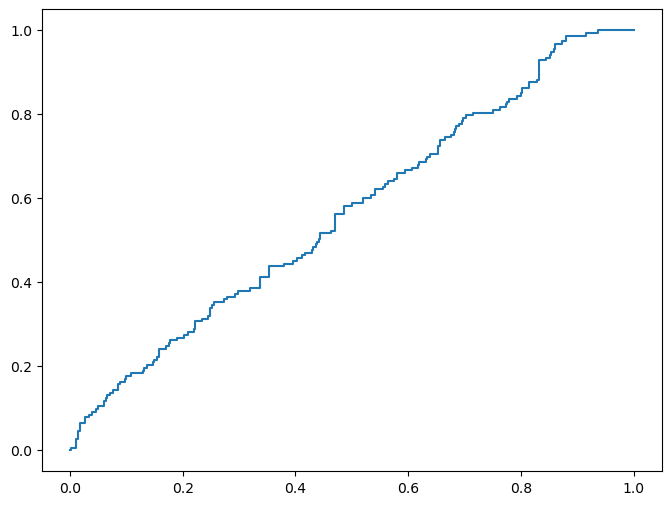

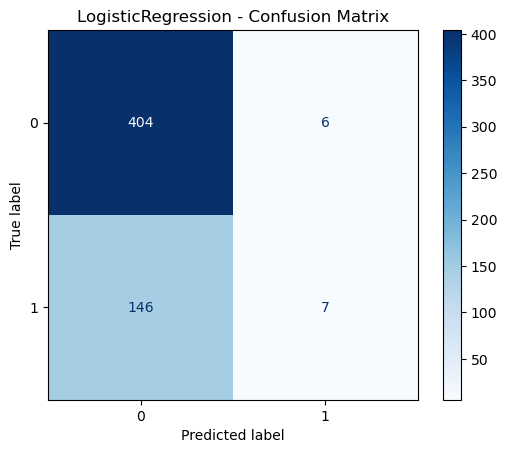

,precision,recall,f1-score,support
0,0.735,0.985,0.842,410.00
1,0.538,0.046,0.084,153.00
accuracy,0.730,0.730,0.730,0.73
macro avg,0.637,0.516,0.463,563.00
weighted avg,0.681,0.730,0.636,563.00


=== DecisionTree ===


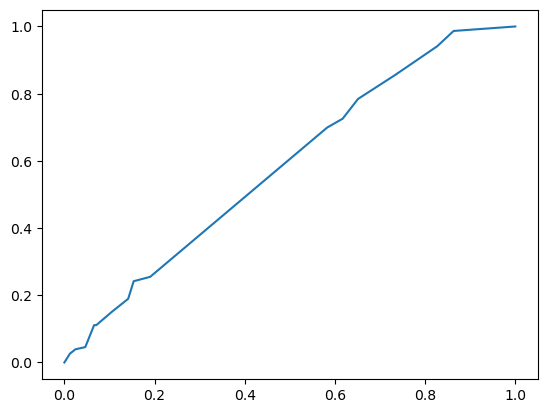

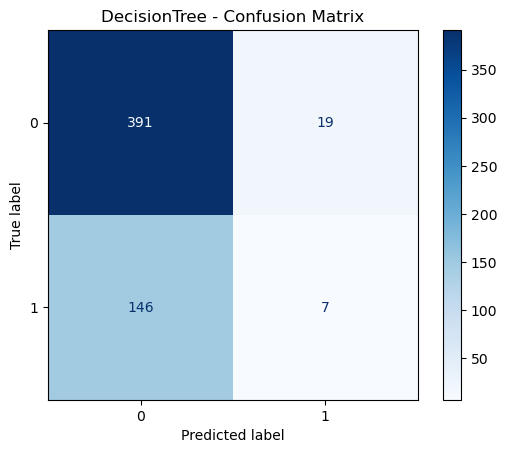

,precision,recall,f1-score,support
0,0.728,0.954,0.826,410.000
1,0.269,0.046,0.078,153.000
accuracy,0.707,0.707,0.707,0.707
macro avg,0.499,0.500,0.452,563.000
weighted avg,0.603,0.707,0.623,563.000


=== RandomForest ===


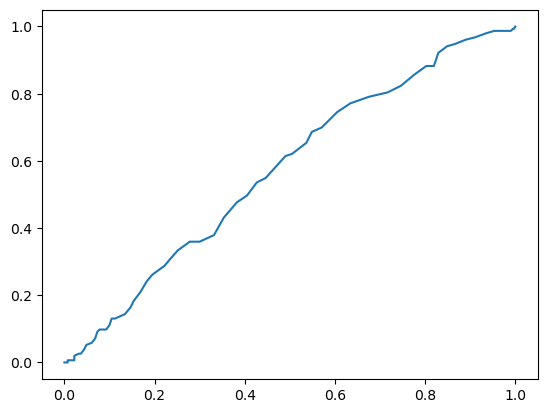

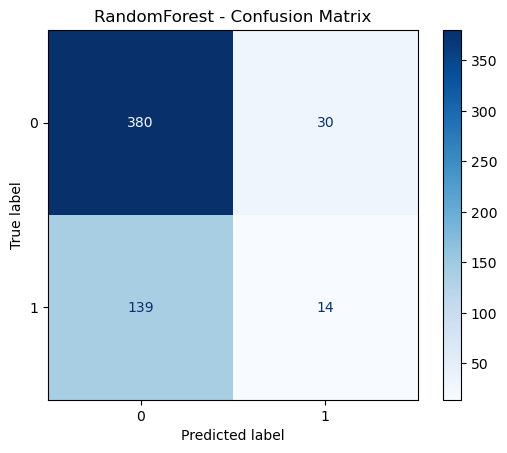

,precision,recall,f1-score,support
0,0.732,0.927,0.818,410.0
1,0.318,0.092,0.142,153.0
accuracy,0.700,0.700,0.700,0.7
macro avg,0.525,0.509,0.480,563.0
weighted avg,0.620,0.700,0.634,563.0


=== GradientBoosting ===


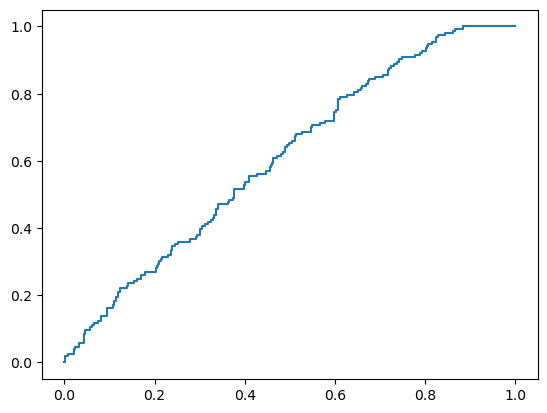

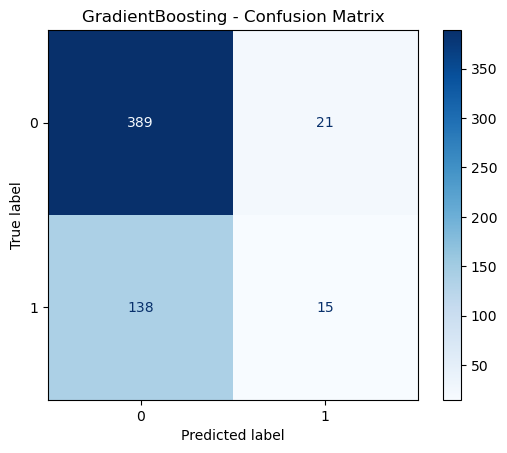

,precision,recall,f1-score,support
0,0.738,0.949,0.830,410.000
1,0.417,0.098,0.159,153.000
accuracy,0.718,0.718,0.718,0.718
macro avg,0.577,0.523,0.495,563.000
weighted avg,0.651,0.718,0.648,563.000


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


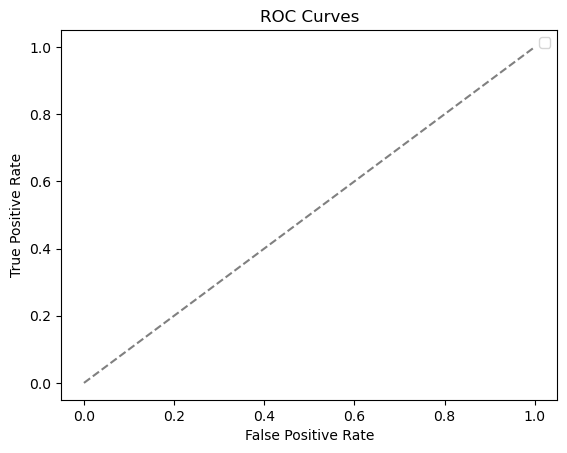

In [43]:
# Cell 8: Evaluate models + ROC + Confusion Matrix + Metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

def plot_confusion_and_metrics(y_true, y_pred, labels=[0,1], title="Confusion Matrix"):
    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(cmap=plt.cm.Blues)
    plt.title(title)
    plt.show()

    # Classification report
    cr = classification_report(y_true, y_pred, target_names=[str(l) for l in labels], output_dict=True)
    cr_df = pd.DataFrame(cr).T
    display(cr_df.round(3))  # hiển thị bảng đẹp trong Jupyter

plt.figure(figsize=(8,6))
results = {}

for name, pipe in fitted_models.items():
    clf = pipe.named_steps['clf']
    probs = pipe.predict_proba(X_test)[:,1]
    preds = (probs >= 0.5).astype(int)

    # ROC AUC & Average Precision
    roc_auc = roc_auc_score(y_test, probs)
    ap = average_precision_score(y_test, probs)

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test, probs)
    if len(fpr) > 0 and len(tpr) > 0:
        plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.3f})")


    # Confusion matrix + metrics table
    print(f"=== {name} ===")
    plot_confusion_and_metrics(y_test, preds, labels=[0,1], title=f"{name} - Confusion Matrix")

    # Feature importances
    feat_imp = getattr(clf, 'feature_importances_', None)
    results[name] = {
        'roc_auc': roc_auc,
        'average_precision': ap,
        'feature_importances': feat_imp
    }

plt.plot([0,1],[0,1],'--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend()
plt.show()



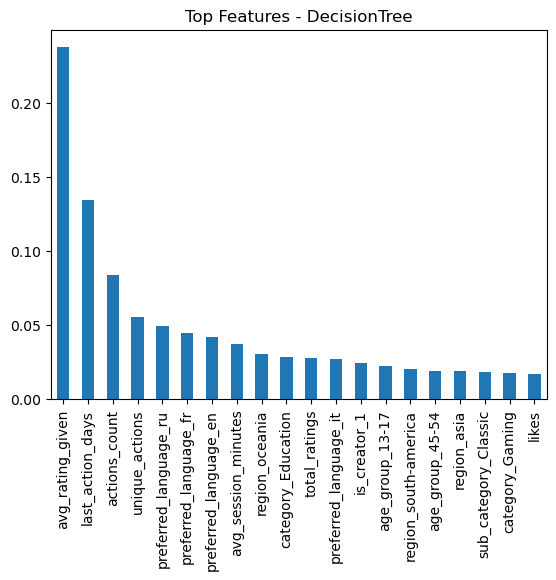

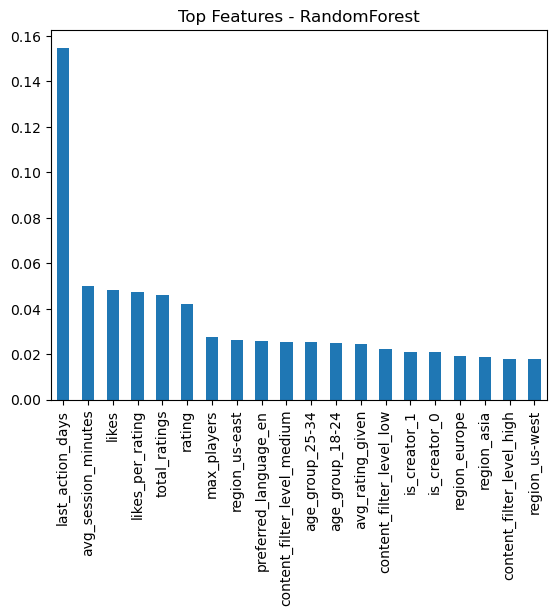

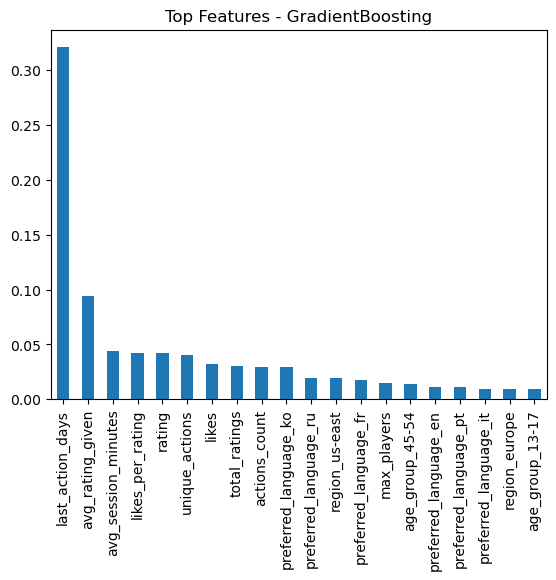

In [44]:
# Cell 9: Feature importance
for name, r in results.items():
    if r['feature_importances'] is not None:
        numeric_names = numeric
        ohe = preprocessor.named_transformers_['cat'].named_steps['onehot']
        try:
            ohe_names = ohe.get_feature_names_out(categorical)
        except:
            ohe_names = []
        feature_names = numeric_names + list(ohe_names)
        fi = pd.Series(r['feature_importances'], index=feature_names).sort_values(ascending=False)
        fi.head(20).plot(kind='bar', title=f'Top Features - {name}')
        plt.show()


In [36]:
def recommend_topN(user_id, users, worlds, model, N=5):
    """
    Recommend top-N worlds for a given user using a trained model.
    Returns a DataFrame with world_id and predicted score.
    """
    import pandas as pd


    pairs = pd.DataFrame({
        "user_id": [user_id]*len(worlds),
        "world_id": worlds['world_id'].tolist()
    })

    user_cols = ['user_id','is_creator','region','preferred_language','age_group','content_filter_level']
    pairs = pairs.merge(users[user_cols], on='user_id', how='left')
    world_cols = ['world_id','category','sub_category','avg_session_minutes','rating','total_ratings',
                  'likes','max_players','is_featured']
    pairs = pairs.merge(worlds[world_cols], on='world_id', how='left')
    numeric_cols = ['avg_session_minutes','rating','total_ratings','likes','max_players',
                    'actions_count','unique_actions','avg_rating_given','last_action_days','likes_per_rating']
    for c in numeric_cols:
        if c in pairs.columns:
            pairs[c] = pd.to_numeric(pairs[c], errors='coerce').fillna(0)
        else:
            pairs[c] = 0

    # Xử lý các cột categorical
    cat_cols = ['is_creator','region','preferred_language','age_group','content_filter_level',
                'category','sub_category','is_featured']
    for c in cat_cols:
        if c in pairs.columns:
            pairs[c] = pairs[c].fillna('missing')
        else:
            pairs[c] = 'missing'

    # Chuẩn bị dữ liệu prediction
    X_pred = pairs[numeric_cols + cat_cols]

    # Dự đoán score
    pairs['score'] = model.predict_proba(X_pred)[:,1]

    # Lấy top-N
    topN = pairs.sort_values('score', ascending=False).head(N)
    return topN[['world_id','score']]



In [37]:
recommend_topN("U730046", users, worlds, fitted_models['LogisticRegression'], N=5)


,world_id,score
65,W9797750,0.162057
15,W3198928,0.150970
41,W2818883,0.146420
74,W5926420,0.145665
23,W1793363,0.143240
